In [1]:
#conda activate TLS
#pip uninstall pymaftools
#pip install --no-cache-dir git+https://github.com/xu62u4u6/pymaftools.git
from pymaftools import *
import sys
sys.path.append("/home/data/data_YM313112004/TLS_model/code/utils/")
cancer_type = "PAAD"
random_seed = 42

In [2]:
# 不用重啟 kernel，Notebook 就會自動載入更新後的函式
%load_ext autoreload
%autoreload 2

### Cancer-specific TLS signatures

{'RNA_CLEC17A', 'RNA_PIK3CD', 'Meth_cg16829924', 'RNA_PAX5', 'RNA_TCL1A', 'RNA_CD48', 'RNA_FCER2', 'RNA_ADRB2', 'RNA_FCRL1'}
{'RNA_FCRLA', 'RNA_IL16', 'Meth_cg16829924', 'RNA_MT-CO3', 'RNA_TCL1A', 'RNA_CD48', 'RNA_MT-ND3', 'RNA_IKZF1', 'RNA_GPR18', 'RNA_FCRL1', 'RNA_CLEC17A', 'RNA_CCR2', 'RNA_PIK3CD', 'RNA_ADAMTS3', 'RNA_PAX5', 'RNA_ETS1', 'RNA_TGFB2', 'RNA_CD79B', 'RNA_CR2', 'RNA_CD22', 'RNA_FCER2', 'RNA_ADRB2', 'RNA_CCR4', 'RNA_CXCL13'}


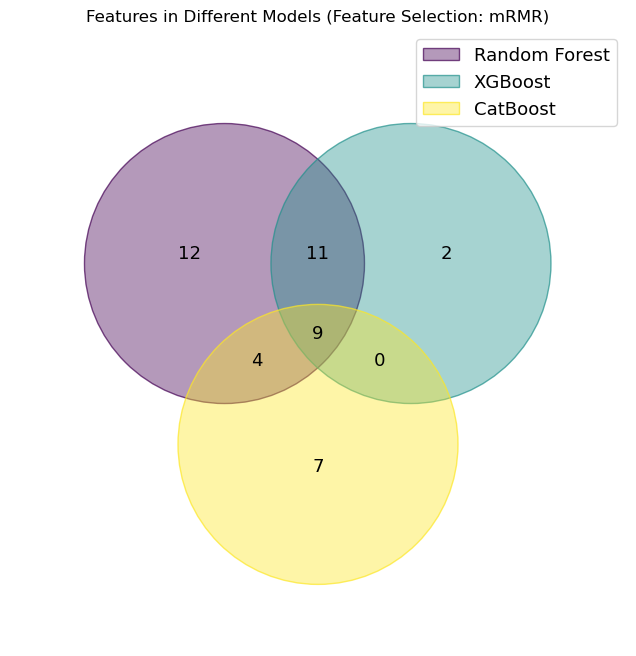

In [3]:
from venn import venn
import matplotlib.pyplot as plt

cancer_type = "PAAD"
top_features_rf = np.load(f"/home/data/data_YM313112004/TLS_model/results/{cancer_type}/selected_features/top_features_concat_mrmr_rf_{random_seed}.npy", allow_pickle=True)
top_features_xgb = np.load(f"/home/data/data_YM313112004/TLS_model/results/{cancer_type}/selected_features/top_features_concat_mrmr_xgb_{random_seed}.npy", allow_pickle=True)
top_features_cat = np.load(f"/home/data/data_YM313112004/TLS_model/results/{cancer_type}/selected_features/top_features_concat_mrmr_catboost_{random_seed}.npy", allow_pickle=True)

datasets = {
    "Random Forest": set(top_features_rf),
    "XGBoost": set(top_features_xgb),
    "CatBoost": set(top_features_cat) 
}

print(set(top_features_rf) & set(top_features_xgb) & set(top_features_cat))
print(set(top_features_rf) & set(top_features_xgb) | set(top_features_rf) & set(top_features_cat) | set(top_features_xgb) & set(top_features_cat))
v = venn(datasets)
plt.title("Features in Different Models (Feature Selection: mRMR)")
plt.show()

### Consensus TLS signatures

{'RNA_CLEC17A', 'RNA_CR2'}
{'RNA_FCRL2', 'RNA_CLEC17A', 'RNA_MS4A1', 'RNA_FCRLA', 'RNA_PAX5', 'RNA_TCL1A', 'RNA_CNR2', 'RNA_CR2', 'RNA_FCER2', 'RNA_CD19', 'RNA_BLK', 'RNA_FCRL1'}


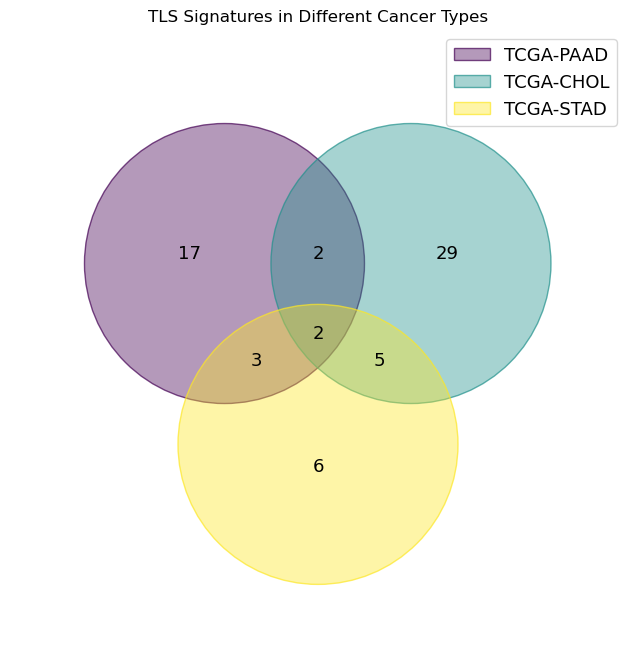

In [4]:
from venn import venn
import matplotlib.pyplot as plt

top_features_CHOL = np.load(f"/home/data/data_YM313112004/TLS_model/results/CHOL/selected_features/TLS_signatures_{random_seed}.npy", allow_pickle=True)
top_features_PAAD = np.load(f"/home/data/data_YM313112004/TLS_model/results/PAAD/selected_features/TLS_signatures_{random_seed}.npy", allow_pickle=True)
top_features_STAD = np.load(f"/home/data/data_YM313112004/TLS_model/results/STAD/selected_features/TLS_signatures_{random_seed}.npy", allow_pickle=True)
datasets = {
    "TCGA-PAAD": set(top_features_PAAD),
    "TCGA-CHOL": set(top_features_CHOL),
    "TCGA-STAD": set(top_features_STAD)
}

print(set(top_features_CHOL) & set(top_features_PAAD) & set(top_features_STAD))
print(set(top_features_CHOL) & set(top_features_PAAD) | set(top_features_CHOL) & set(top_features_STAD) | set(top_features_PAAD) & set(top_features_STAD))
v = venn(datasets)
plt.title("TLS Signatures in Different Cancer Types")
plt.show()

In [5]:
consensus_tls = list(set(top_features_CHOL) & set(top_features_PAAD) | set(top_features_CHOL) & set(top_features_STAD) | set(top_features_PAAD) & set(top_features_STAD))
print(consensus_tls)
arr = np.array(consensus_tls, dtype=object)
np.save(f"/home/data/data_YM313112004/TLS_model/results/all/selected_features/TLS_signatures_consensus_{random_seed}.npy", arr)

['RNA_FCRL2', 'RNA_CLEC17A', 'RNA_MS4A1', 'RNA_FCRLA', 'RNA_PAX5', 'RNA_TCL1A', 'RNA_CNR2', 'RNA_CR2', 'RNA_FCER2', 'RNA_CD19', 'RNA_BLK', 'RNA_FCRL1']


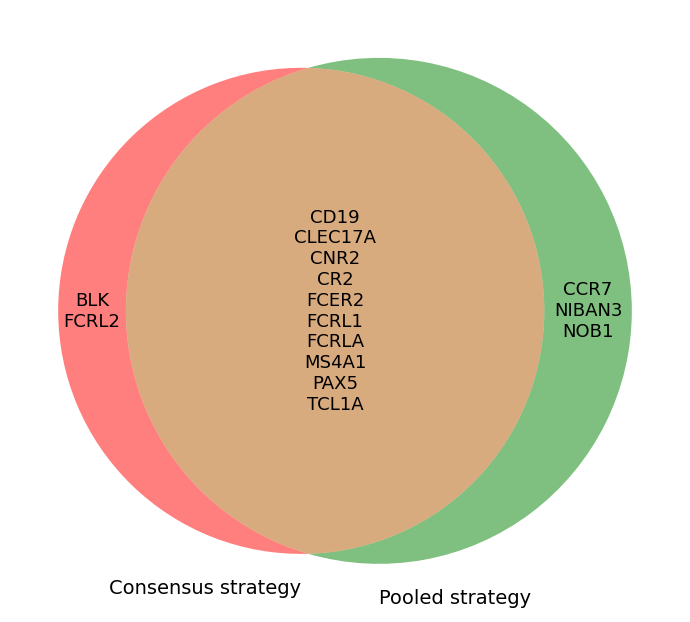

In [6]:
from matplotlib import pyplot as plt
import re
from matplotlib_venn import venn2

# Convert to sets
consensus_list = np.load(f"/home/data/data_YM313112004/TLS_model/results/all/selected_features/TLS_signatures_consensus_42.npy", allow_pickle=True)
pooled_list = np.load(f"/home/data/data_YM313112004/TLS_model/results/all/selected_features/TLS_signatures_42.npy", allow_pickle=True)

# Remove "RNA_" prefix
consensus_list = [re.sub(r"^RNA_", "", x) for x in consensus_list]
pooled_list = [re.sub(r"^RNA_", "", x) for x in pooled_list]

consensus_set = set(consensus_list)
pooled_set = set(pooled_list)

only_consensus = sorted(consensus_set - pooled_set)
only_pooled = sorted(pooled_set - consensus_set)
overlap = sorted(consensus_set & pooled_set)

plt.figure(figsize=(7,7))

venn = venn2(
    [consensus_set, pooled_set],
    set_labels=('Consensus strategy', 'Pooled strategy')
)

for patch in venn.patches:
    if patch:
        patch.set_alpha(0.5)

# Replace counts by genes
venn.get_label_by_id('10').set_text('\n'.join(only_consensus))
venn.get_label_by_id('01').set_text('\n'.join(only_pooled))
venn.get_label_by_id('11').set_text('\n'.join(overlap))

# Font
for label in venn.set_labels:
    label.set_fontsize(14)

for sid in ['10', '01', '11']:
    lbl = venn.get_label_by_id(sid)
    if lbl:
        lbl.set_fontsize(13)

plt.tight_layout()
plt.show()